# Utterance augmentation for intent recognition

Reproducible, Colab-ready adaptation of Madrueño et al., *Neural Computing and Applications* (2025), DOI [10.1007/s00521-025-11642-3](https://doi.org/10.1007/s00521-025-11642-3).

The article's method is **reference utterance → LLM paraphrases → domain-trained word-embedding synonym replacement → cosine-similarity intent detection**. This notebook uses the [authors' public evaluation data](https://github.com/URJCDSLab/utterance-data-augmentation-data), an open Qwen2.5 0.5B instruction model in place of the paper's GPT-4, and Word2Vec trained on the public Reuters corpus in place of the paper's private financial communications. Thus it tests the proposed *mechanism* on the same evaluation utterances, but it is not an exact numerical reproduction of the published results.

**Evaluation rule:** only the nonempty `Reference phrase` cells form positive training seeds. `Similar` is positive test data; `Negatives Left` and `Negatives Right` are negative test data. No test utterance or label is used for augmentation, model fitting, or threshold selection. PR-AUC below means scikit-learn average precision; it is threshold-free.

In [1]:
!pip -q install 'transformers>=4.45,<5' 'sentence-transformers>=3,<6' 'gensim>=4.3,<5' openpyxl nltk

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import io, json, random, re, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import nltk
from nltk.corpus import reuters, stopwords
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Torch device:', DEVICE)

Torch device: cuda


## 1. Load the authors' test data

The GitHub README currently describes different counts from the actual workbooks. The code below prints the counts it reads and checks the reference and test split. Repeated reference phrases in the combined workbook are deduplicated.

In [3]:
BASE = 'https://raw.githubusercontent.com/URJCDSLab/utterance-data-augmentation-data/main/data/'
FILES = {
    'General': 'intents_general_paraphrases.xlsx',
    'General + financial': 'intents_general_financial_paraphrases.xlsx',
}

def load_problem(filename):
    with urllib.request.urlopen(BASE + filename) as response:
        frame = pd.read_excel(io.BytesIO(response.read()))
    refs = list(dict.fromkeys(frame['Reference phrase'].dropna().astype(str).str.strip()))
    positive = frame['Similar'].dropna().astype(str).str.strip().tolist()
    negative = (frame['Negatives Left'].dropna().astype(str).str.strip().tolist()
                + frame['Negatives Right'].dropna().astype(str).str.strip().tolist())
    test_text = positive + negative
    test_y = np.array([1] * len(positive) + [0] * len(negative))
    assert len(refs) > 0 and len(positive) > 0 and len(negative) > 0
    assert not (set(x.lower() for x in refs) & set(x.lower() for x in test_text)), 'Reference/test overlap'
    return {'refs': refs, 'text': test_text, 'y': test_y}

problems = {name: load_problem(file) for name, file in FILES.items()}
pd.DataFrame([{'problem': name, 'unique_refs': len(p['refs']),
               'positive_test': int(p['y'].sum()), 'negative_test': int((1-p['y']).sum())}
              for name, p in problems.items()])

,problem,unique_refs,positive_test,negative_test
0,General,8,125,250
1,General + financial,13,175,350


## 2. Train domain word embeddings on independent text

Reuters news is a public financial/news corpus. Word2Vec uses the paper's CBOW setting, 200 dimensions, context window 2, and minimum count 5. Its vocabulary is less specialized than the proprietary surveillance corpus in the paper. All model selection values below are fixed before viewing test scores.

In [4]:
nltk.download('reuters', quiet=True)
nltk.download('stopwords', quiet=True)
corpus = [reuters.words(fid) for fid in reuters.fileids()]
sentences = [[w.lower() for w in doc if re.fullmatch(r"[A-Za-z]+", w)] for doc in corpus]
sentences = [s for s in sentences if len(s) >= 3]
w2v = Word2Vec(sentences=sentences, vector_size=200, window=2, min_count=5,
               sg=0, workers=2, seed=SEED, epochs=10)
print(f'{len(sentences):,} Reuters documents; {len(w2v.wv):,} learned word vectors')

10,727 Reuters documents; 10,427 learned word vectors


## 3. Generate zero-shot paraphrases with an open instruction LLM

This step requires no API key. A 0.5B model is chosen so the notebook also runs on a free Colab CPU, although a GPU is faster. The generation prompt contains the reference phrase alone; no labeled test examples are supplied.

In [5]:
MODEL_ID = 'Qwen/Qwen2.5-0.5B-Instruct'
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
llm = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype='auto').to(DEVICE)
llm.eval()

def clean_paraphrases(raw, original):
    lines = re.split(r'\n+', raw)
    out = []
    for line in lines:
        line = re.sub(r'^\s*(?:[-*]|\d+[.)])\s*', '', line).strip().strip('"\'` ')
        line = re.sub(r'^(?:paraphrase|alternative)\s*\d*\s*:\s*', '', line, flags=re.I)
        if not line or len(line.split()) > 18 or len(line) > 150:
            continue
        if line.lower() == original.lower() or line.lower() in {x.lower() for x in out}:
            continue
        out.append(line)
    return out[:4]

@torch.inference_mode()
def generate_paraphrases(original):
    messages = [{'role': 'user', 'content':
        'Write exactly four short English paraphrases of this utterance. Preserve its intent and direction (for example, increase must not become decrease). '
        'Vary wording and grammar. Return only four numbered lines, no explanation.\nUtterance: ' + original}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors='pt').to(DEVICE)
    generated = llm.generate(**inputs, max_new_tokens=120, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    raw = tokenizer.decode(generated[0, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    return clean_paraphrases(raw, original), raw

all_refs = list(dict.fromkeys(r for p in problems.values() for r in p['refs']))
paraphrases, raw_generations = {}, {}
start = time.time()
for i, ref in enumerate(all_refs, 1):
    paraphrases[ref], raw_generations[ref] = generate_paraphrases(ref)
    print(f'{i:02d}/{len(all_refs)} {ref!r}: {len(paraphrases[ref])} paraphrases')
print(f'LLM generation: {(time.time()-start)/60:.1f} min')
display(pd.DataFrame([(k, v) for k, vals in paraphrases.items() for v in vals],
                     columns=['reference', 'LLM paraphrase']).head(25))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

... (2 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


01/13 'increase the index': 4 paraphrases
02/13 'decrease the index': 2 paraphrases
03/13 'talk on whatsapp': 4 paraphrases
04/13 'give a hint': 4 paraphrases
05/13 'falsify trades': 4 paraphrases
06/13 'need inside information': 4 paraphrases
07/13 'meet offline': 4 paraphrases
08/13 'someone is surveilling': 4 paraphrases
09/13 'increase the nasdaq': 4 paraphrases
10/13 'increase the nikkei': 4 paraphrases
11/13 'increase the dax': 4 paraphrases
12/13 'decrease the libor': 4 paraphrases
13/13 'decrease the bund': 4 paraphrases
LLM generation: 0.8 min


,reference,LLM paraphrase
0,increase the index,Increase the number of indices
1,increase the index,Add more indices to your list
2,increase the index,Expand the scope of indices
3,increase the index,Extend the range of indices
4,decrease the index,Reduce the index
5,decrease the index,Lower the index
6,talk on whatsapp,Chat on WhatsApp
7,talk on whatsapp,Discuss via WhatsApp
8,talk on whatsapp,Share on WhatsApp
9,talk on whatsapp,Exchange messages on WhatsApp


## 4. Construct the ablations

For each reference word, find up to five nearest Word2Vec terms above cosine similarity 0.5, then substitute matching whole words in a sentence. Stopwords are excluded and a maximum of two nearest terms is used per sentence to control the size of the generated set. The original utterances are retained in every training set. These bounds make this a computationally small adaptation of the paper's synonym stage.

In [6]:
STOP = set(stopwords.words('english'))
SIM_THRESHOLD, TOP_N, MAX_PER_UTTERANCE = 0.5, 5, 2

def synonym_map(ref):
    mapping = {}
    for word in set(re.findall(r"[A-Za-z]+", ref.lower())):
        if len(word) < 4 or word in STOP or word not in w2v.wv:
            continue
        mapping[word] = [candidate for candidate, similarity in w2v.wv.most_similar(word, topn=TOP_N)
                         if similarity >= SIM_THRESHOLD and candidate.isalpha()
                         and candidate != word and candidate not in STOP]
    return mapping

def replace_words(text, mapping):
    generated = []
    for original_word, candidates in mapping.items():
        if not re.search(r'\b' + re.escape(original_word) + r'\b', text, flags=re.I):
            continue
        for candidate in candidates[:MAX_PER_UTTERANCE]:
            variant = re.sub(r'\b' + re.escape(original_word) + r'\b', candidate,
                             text, count=1, flags=re.I)
            if variant.lower() != text.lower(): generated.append(variant)
    return generated

def unique(items):
    return list(dict((x.lower(), x) for x in items if isinstance(x, str) and x.strip()).values())

maps = {ref: synonym_map(ref) for ref in all_refs}
training = {}
for problem, p in problems.items():
    refs = p['refs']
    llm_text = [v for ref in refs for v in paraphrases[ref]]
    w2v_text = [v for ref in refs for v in replace_words(ref, maps[ref])]
    combined = [v for ref in refs for phrase in [ref] + paraphrases[ref]
                for v in replace_words(phrase, maps[ref])]
    training[problem] = {
        'Original': unique(refs),
        'LLM only': unique(refs + llm_text),
        'Word2Vec only': unique(refs + w2v_text),
        'LLM + Word2Vec': unique(refs + llm_text + combined),
    }

display(pd.DataFrame([{'problem': p, 'method': m, 'training_utterances': len(v)}
                      for p, sets in training.items() for m, v in sets.items()]))
display(pd.DataFrame([(ref, word, ', '.join(cands[:3])) for ref, mp in maps.items()
                      for word, cands in mp.items() if cands],
                     columns=['reference', 'source word', 'nearest replacement']).head(25))

,problem,method,training_utterances
0,General,Original,8
1,General,LLM only,38
2,General,Word2Vec only,32
3,General,LLM + Word2Vec,84
4,General + financial,Original,13
5,General + financial,LLM only,63
6,General + financial,Word2Vec only,51
7,General + financial,LLM + Word2Vec,149


,reference,source word,nearest replacement
0,increase the index,index,"indicator, gdp, silver"
1,increase the index,increase,"decrease, rise, drop"
2,decrease the index,index,"indicator, gdp, silver"
3,decrease the index,decrease,"increase, jump, drop"
4,talk on whatsapp,talk,"fear, talked, nervous"
5,give a hint,hint,"surprises, barring, proof"
6,give a hint,give,"disclose, accept, identify"
7,falsify trades,trades,"frustrated, fixing, rebate"
8,need inside information,inside,"worrying, dormant, watching"
9,need inside information,information,"views, arrangements, alternatives"


## 5. Intent recognition and held-out scoring

As in the paper, each test utterance receives the **maximum cosine similarity** to any positive training utterance. This score is evaluated against its held-out positive/negative label. MiniLM sentence embeddings and a TF-IDF representation are shown. TF-IDF vocabulary is fit once on Reuters plus original reference phrases, then held fixed across all methods.

In [7]:
sbert = SentenceTransformer('sentence-transformers/paraphrase-MiniLM-L6-v2', device=DEVICE)
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1,
                         max_features=80000, norm='l2')
tfidf.fit([' '.join(s) for s in sentences] + all_refs)

results, scores = [], {}
for problem, p in problems.items():
    y = p['y']
    test_sbert = sbert.encode(p['text'], convert_to_numpy=True, normalize_embeddings=True,
                              batch_size=64, show_progress_bar=False)
    test_tfidf = tfidf.transform(p['text'])
    for method, texts in training[problem].items():
        train_sbert = sbert.encode(texts, convert_to_numpy=True, normalize_embeddings=True,
                                   batch_size=64, show_progress_bar=False)
        train_tfidf = tfidf.transform(texts)
        for encoder, vals in [('MiniLM', (test_sbert @ train_sbert.T).max(axis=1)),
                              ('TF-IDF', cosine_similarity(test_tfidf, train_tfidf).max(axis=1))]:
            ap = average_precision_score(y, vals)
            results.append({'problem': problem, 'encoder': encoder, 'method': method,
                            'train_size': len(texts), 'average_precision': ap})
            scores[(problem, encoder, method)] = vals

result_df = pd.DataFrame(results)
display(result_df.pivot_table(index=['problem', 'encoder'], columns='method',
                              values='average_precision').round(3))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

method                       LLM + Word2Vec  LLM only  Original  Word2Vec only
problem             encoder                                                   
General             MiniLM            0.754     0.758     0.736          0.728
                    TF-IDF            0.515     0.512     0.471          0.477
General + financial MiniLM            0.698     0.713     0.713          0.687
                    TF-IDF            0.590     0.588     0.566          0.569

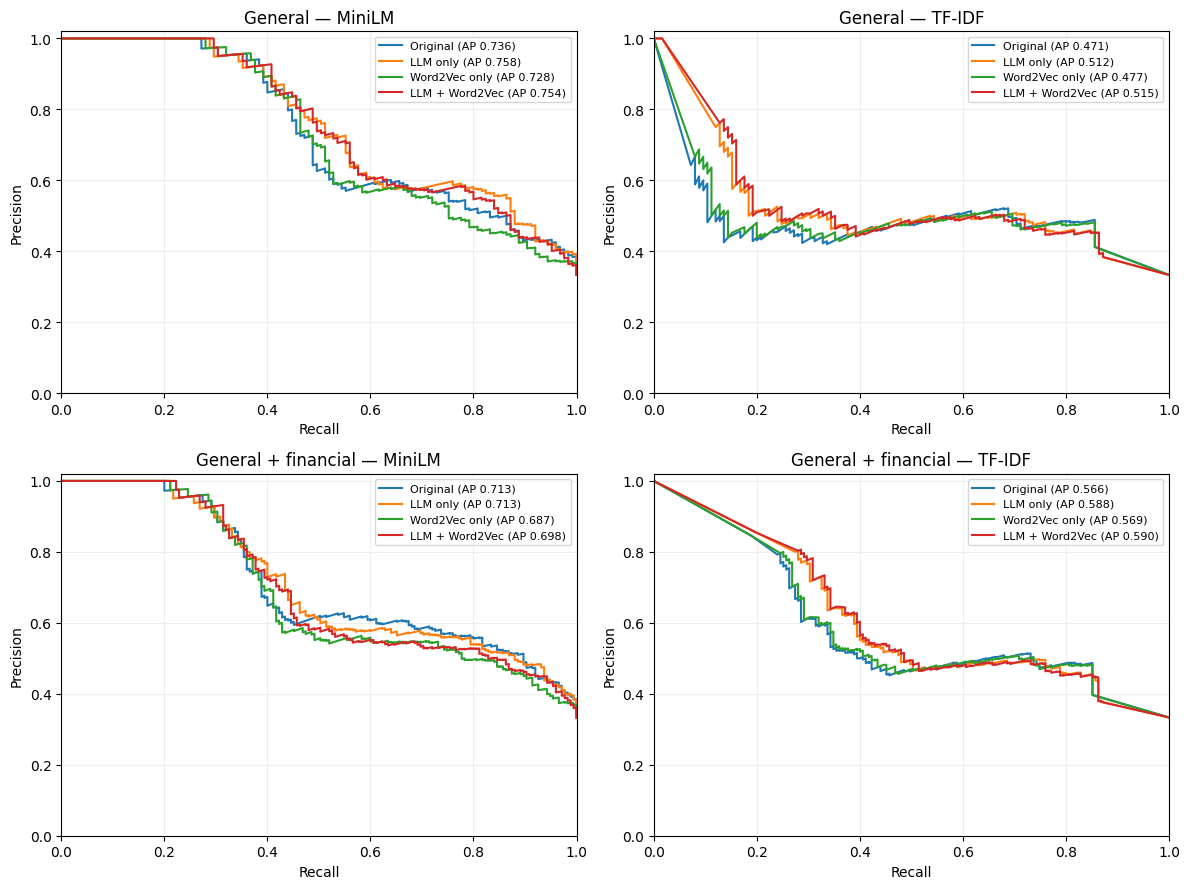

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (problem, p) in enumerate(problems.items()):
    for col, encoder in enumerate(['MiniLM', 'TF-IDF']):
        ax = axes[row, col]
        for method in training[problem]:
            vals = scores[(problem, encoder, method)]
            precision, recall, _ = precision_recall_curve(p['y'], vals)
            ap = average_precision_score(p['y'], vals)
            ax.plot(recall, precision, label=f'{method} (AP {ap:.3f})')
        ax.set(xlabel='Recall', ylabel='Precision', title=f'{problem} — {encoder}',
               xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig('pr_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Conclusions and saved results

The next cell states what this particular run shows. Compare its scores only within each dataset and encoder. The paper's GPT-4 model, private corpus, prompt sampling, and larger synonym expansion can produce different numbers. Word-vector neighbors may also change an utterance's meaning; review generated samples before using them in a deployed classifier.

In [9]:
for problem in problems:
    print('\n' + problem)
    for encoder in ['MiniLM', 'TF-IDF']:
        part = result_df[(result_df.problem == problem) & (result_df.encoder == encoder)]
        values = dict(zip(part.method, part.average_precision))
        best = max(values, key=values.get)
        print(f'  {encoder}: best = {best} ({values[best]:.3f}); '
              f'combined − original = {values["LLM + Word2Vec"]-values["Original"]:+.3f}; '
              f'combined − LLM = {values["LLM + Word2Vec"]-values["LLM only"]:+.3f}')

result_df.to_csv('results.csv', index=False)
with open('run_details.json', 'w') as f:
    json.dump({'paper_doi': '10.1007/s00521-025-11642-3',
               'llm': MODEL_ID, 'sentence_model': 'sentence-transformers/paraphrase-MiniLM-L6-v2',
               'word_corpus': 'NLTK Reuters', 'seed': SEED,
               'problem_counts': {name: {'reference_count': len(p['refs']),
                                        'positive_test': int(p['y'].sum()),
                                        'negative_test': int((1-p['y']).sum())}
                                  for name, p in problems.items()},
               'paraphrases': paraphrases, 'synonym_maps': maps}, f, indent=2)
print('\nSaved results.csv, run_details.json, and pr_curves.png in the Colab runtime.')


General
  MiniLM: best = LLM only (0.758); combined − original = +0.018; combined − LLM = -0.004
  TF-IDF: best = LLM + Word2Vec (0.515); combined − original = +0.044; combined − LLM = +0.003

General + financial
  MiniLM: best = Original (0.713); combined − original = -0.015; combined − LLM = -0.015
  TF-IDF: best = LLM + Word2Vec (0.590); combined − original = +0.023; combined − LLM = +0.002

Saved results.csv, run_details.json, and pr_curves.png in the Colab runtime.
